# PHÂN TÍCH VÀ TRỰC QUAN HÓA DỮ LIỆU E-COMMERCE

**Dataset:** E-Commerce Customer Behavior & Sales 2020–2026

Notebook thực hiện phân tích và trực quan hóa dữ liệu kinh doanh với nội dung:

1. Mô tả tổng quan: số đơn, số khách, số nước, số nhóm hàng và tổng doanh thu.

Dữ liệu sử dụng được lấy từ thư mục `data/cleaned`, đã qua quá trình tiền xử lý và làm sạch.

## 1. CHUẨN BỊ MÔI TRƯỜNG

Import các thư viện cần thiết để đọc, xử lý và trực quan hóa dữ liệu.

In [1]:
# Import các thư viện
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập hiển thị
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:,.2f}'.format)

sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.unicode_minus'] = False

print("Các thư viện đã được import thành công!")

Các thư viện đã được import thành công!


In [2]:
# Tạo thư mục lưu các biểu đồ kết quả
import os

os.makedirs('../exports/archive_static_png', exist_ok=True)

print("Đã tạo thư mục exports/archive_static_png!")

Đã tạo thư mục exports/archive_static_png!


## 2. ĐỌC DỮ LIỆU ĐÃ LÀM SẠCH

Sử dụng các bộ dữ liệu đã được tiền xử lý trong thư mục `data/cleaned` để thực hiện phân tích.

In [3]:
# Đọc dữ liệu đã làm sạch
orders = pd.read_csv('../data/cleaned/orders_cleaned.csv')
customers = pd.read_csv('../data/cleaned/customers_cleaned.csv')

print("Đọc dữ liệu thành công!")
print("Orders:", orders.shape)
print("Customers:", customers.shape)

Đọc dữ liệu thành công!
Orders: (25000, 29)
Customers: (8000, 20)


## 2.1. Xác định dữ liệu sử dụng

- `orders`: Dữ liệu đơn hàng, phục vụ tính số đơn, số khách có giao dịch, số nhóm hàng và tổng doanh thu.
- `customers`: Dữ liệu khách hàng, phục vụ xác định số quốc gia và quy mô tệp khách hàng.

Các bảng dữ liệu được sử dụng theo đúng mục đích của từng câu hỏi.

# 3. CÂU 1. MÔ TẢ TỔNG QUAN: SỐ ĐƠN, SỐ KHÁCH, SỐ NƯỚC, SỐ NHÓM HÀNG VÀ TỔNG DOANH THU

Mục tiêu: Sử dụng các chỉ số tổng quan để mô tả quy mô hoạt động kinh doanh, bao gồm số lượng đơn hàng, khách hàng, quốc gia, nhóm hàng và tổng doanh thu.

In [4]:
# Kiểm tra các cột phục vụ Câu 1
print("ORDERS:")
print(orders.columns.tolist())

print("\nCUSTOMERS:")
print(customers.columns.tolist())

ORDERS:
['order_id', 'customer_id', 'order_date', 'year', 'month', 'quarter', 'day_of_week', 'product_name', 'category', 'unit_price_usd', 'quantity', 'subtotal_usd', 'discount_pct', 'discount_amount_usd', 'shipping_fee_usd', 'tax_pct', 'tax_amount_usd', 'total_amount_usd', 'payment_method', 'device_used', 'delivery_days', 'delivery_date', 'order_status', 'returned', 'customer_rating', 'session_duration_minutes', 'pages_viewed_before_purchase', 'is_repeat_customer', 'rating_provided']

CUSTOMERS:
['customer_id', 'country', 'age', 'gender', 'membership_tier', 'registration_date', 'total_orders', 'total_spend_usd', 'avg_order_value_usd', 'days_since_last_purchase', 'preferred_category', 'preferred_device', 'preferred_payment_method', 'acquisition_channel', 'reviews_given', 'avg_review_score', 'returns_made', 'wishlist_items', 'newsletter_subscribed', 'churned']


In [5]:
# Tính các chỉ số tổng quan
total_orders = orders['order_id'].nunique()
total_customers = orders['customer_id'].nunique()
total_countries = customers['country'].nunique()
total_categories = orders['category'].nunique()
total_revenue = orders['total_amount_usd'].sum()

# Tổng hợp kết quả
kpi_summary = pd.DataFrame({
    'Chỉ số': [
        'Tổng số đơn hàng',
        'Số khách hàng có phát sinh đơn',
        'Số quốc gia',
        'Số nhóm hàng',
        'Tổng doanh thu (USD)'
    ],
    'Giá trị': [
        total_orders,
        total_customers,
        total_countries,
        total_categories,
        total_revenue
    ]
})

display(kpi_summary)

,Chỉ số,Giá trị
0,Tổng số đơn hàng,"25,000.00"
1,Số khách hàng có phát sinh đơn,"7,663.00"
2,Số quốc gia,20.00
3,Số nhóm hàng,14.00
4,Tổng doanh thu (USD),"3,136,404.66"


## 3.1. Trực quan hóa các chỉ số tổng quan

Sử dụng biểu đồ KPI Cards để thể hiện năm chỉ số chính, giúp người xem nhanh chóng nắm bắt quy mô hoạt động kinh doanh.

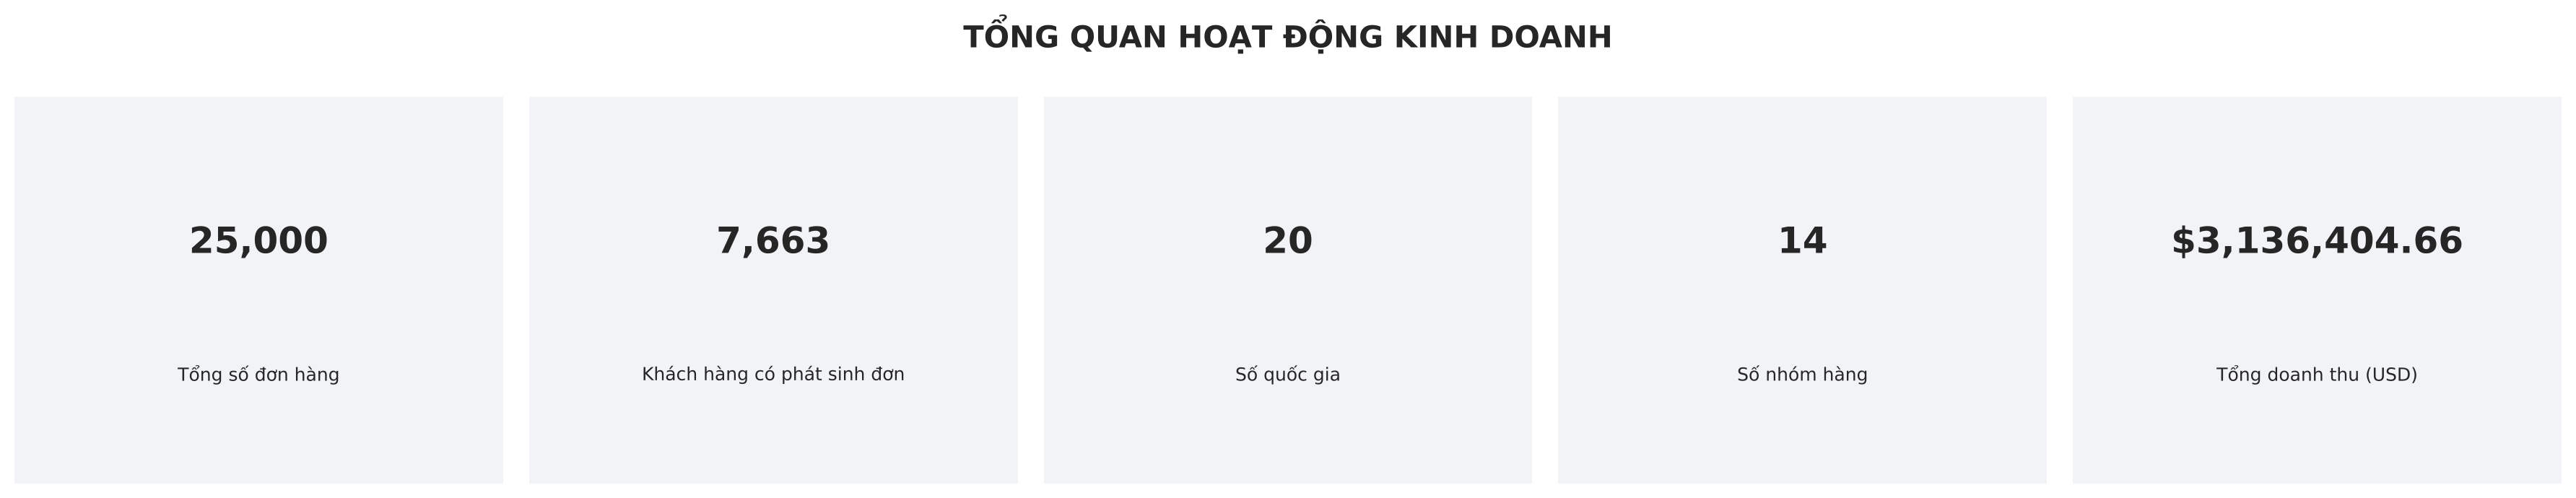

In [6]:
# Chuẩn bị dữ liệu hiển thị KPI
kpi_labels = [
    'Tổng số đơn hàng',
    'Khách hàng có phát sinh đơn',
    'Số quốc gia',
    'Số nhóm hàng',
    'Tổng doanh thu (USD)'
]

kpi_values = [
    f'{total_orders:,}',
    f'{total_customers:,}',
    f'{total_countries:,}',
    f'{total_categories:,}',
    f'${total_revenue:,.2f}'
]

# Tạo biểu đồ KPI Cards
fig, axes = plt.subplots(1, 5, figsize=(18, 3.5))

for ax, label, value in zip(axes, kpi_labels, kpi_values):
    ax.text(0.5, 0.62, value, ha='center', va='center',
            fontsize=18, fontweight='bold')
    ax.text(0.5, 0.28, label, ha='center', va='center',
            fontsize=9, wrap=True)

    ax.set_facecolor('#F1F3F6')
    ax.set_xticks([])
    ax.set_yticks([])

    for spine in ax.spines.values():
        spine.set_visible(False)

fig.suptitle(
    'TỔNG QUAN HOẠT ĐỘNG KINH DOANH',
    fontsize=15,
    fontweight='bold'
)

plt.tight_layout()
plt.savefig(
    '../exports/archive_static_png/kpi_overview.png',
    dpi=300,
    bbox_inches='tight'
)
plt.show()

### 3.2. Nhận xét và kết luận

**a. Nhận xét**

- **Số đơn hàng:** Ghi nhận 25.000 đơn hàng, cho thấy quy mô giao dịch tương đối lớn trong phạm vi dữ liệu.
- **Số khách hàng:** Có 7.663 khách hàng phát sinh đơn hàng, phản ánh lượng khách hàng thực sự tham gia hoạt động mua sắm.
- **Phạm vi thị trường:** Hoạt động kinh doanh ghi nhận khách hàng đến từ 20 quốc gia, cho thấy phạm vi tiếp cận thị trường quốc tế.
- **Nhóm hàng:** Có 14 nhóm hàng, thể hiện sự đa dạng trong danh mục sản phẩm kinh doanh.
- **Doanh thu:** Tổng doanh thu đạt 3.136.404,66 USD, phản ánh tổng giá trị giao dịch đáng kể trong tập dữ liệu.

**b. Kết luận**

Nhìn chung, dữ liệu cho thấy hoạt động kinh doanh có quy mô tương đối lớn, tệp khách hàng trải rộng trên nhiều quốc gia và danh mục sản phẩm đa dạng. Tổng doanh thu đạt hơn 3,13 triệu USD. Đây là cơ sở để tiếp tục phân tích sự biến động doanh thu theo thời gian, qua đó nhận diện xu hướng và tính thời vụ trong hoạt động kinh doanh.